# 01 - Exploratory Data Analysis
Har plot ka ek sawaal hai: kaun sa sensor failure se pehle badalta hai, kaun se features redundant hain, aur target imbalanced hai ya nahi.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # notebook 'notebooks/' folder se chal raha hai
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config
sns.set_theme(style="whitegrid")

from src.preprocessing import load_raw, clean
df = clean(load_raw())
df.head()

,machine_id,timestamp,machine_type,air_temperature,temperature,rotational_speed,torque,tool_wear,failure,failure_type
0,M001,2026-01-01 00:00:00,M,301.18,310.44,1554.0,35.94,39.0,0,No Failure
1,M001,2026-01-01 01:00:00,M,301.46,311.61,1627.0,35.04,42.0,0,No Failure
2,M001,2026-01-01 02:00:00,M,302.08,311.52,1529.0,36.93,43.0,0,No Failure
3,M001,2026-01-01 03:00:00,M,301.80,311.08,1636.0,39.83,46.0,0,No Failure
4,M001,2026-01-01 04:00:00,M,303.02,312.27,1480.0,36.99,49.0,0,No Failure


In [2]:
print(df.shape)
print(df.isnull().sum())
print('duplicates:', df.duplicated().sum())
df.describe()

(10000, 10)
machine_id          0
timestamp           0
machine_type        0
air_temperature     0
temperature         0
rotational_speed    0
torque              0
tool_wear           0
failure             0
failure_type        0
dtype: int64
duplicates: 0


,timestamp,air_temperature,temperature,rotational_speed,torque,tool_wear,failure
count,10000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000
mean,2026-01-05 03:30:00,299.801447,309.355397,1512.47120,40.013108,70.013200,0.02960
min,2026-01-01 00:00:00,293.470000,302.380000,1100.00000,22.540000,0.000000,0.00000
25%,2026-01-03 01:45:00,298.630000,308.120000,1403.00000,36.960000,24.000000,0.00000
50%,2026-01-05 03:30:00,299.840000,309.370000,1512.00000,39.910000,60.000000,0.00000
75%,2026-01-07 05:15:00,300.972500,310.650000,1621.00000,43.010000,110.000000,0.00000
max,2026-01-09 07:00:00,305.050000,315.540000,2111.00000,59.290000,205.000000,1.00000
std,NaN,1.796970,1.903284,161.28973,4.619636,52.348605,0.16949


## Class imbalance
Failure rows bahut kam hain, isliye accuracy akeli kaafi nahi hogi.

failure
0    97.04
1     2.96
Name: proportion, dtype: float64


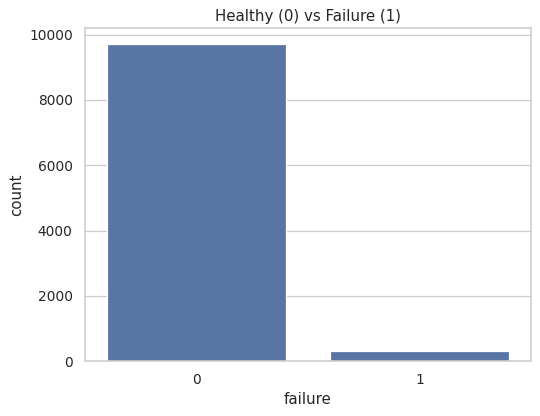

In [3]:
print(df[config.COL_FAILURE].value_counts(normalize=True) * 100)
sns.countplot(data=df, x=config.COL_FAILURE)
plt.title('Healthy (0) vs Failure (1)')
plt.show()

## Healthy vs failed sensor distributions

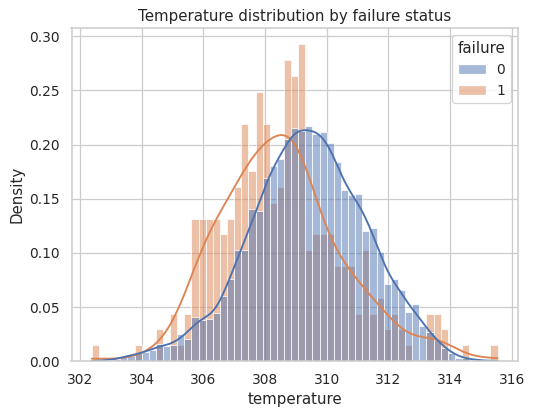

In [4]:
sns.histplot(data=df, x=config.COL_TEMP, hue=config.COL_FAILURE, kde=True, stat='density', common_norm=False)
plt.title('Temperature distribution by failure status')
plt.show()

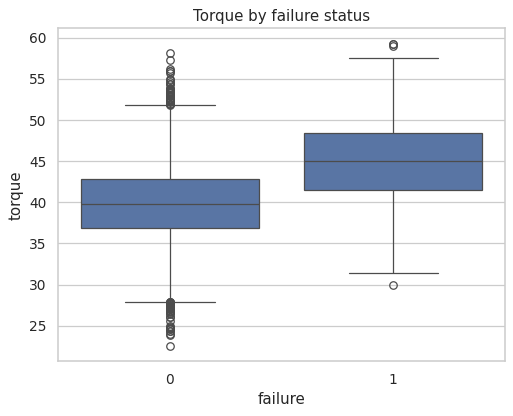

In [5]:
sns.boxplot(data=df, x=config.COL_FAILURE, y=config.COL_TORQUE)
plt.title('Torque by failure status')
plt.show()

## Correlation heatmap

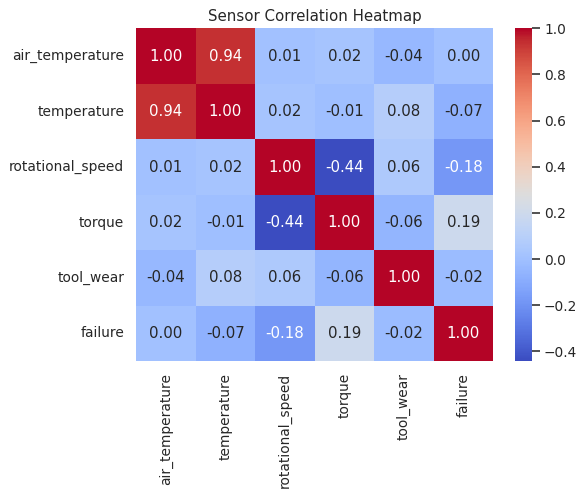

In [6]:
cols = [config.COL_AIR_TEMP, config.COL_TEMP, config.COL_SPEED, config.COL_TORQUE, config.COL_WEAR, config.COL_FAILURE]
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Sensor Correlation Heatmap')
plt.show()

## Failure types and machine-wise failures

In [7]:
print(df[config.COL_FAILURE_TYPE].value_counts())
df.groupby(config.COL_MACHINE)[config.COL_FAILURE].sum().sort_values(ascending=False).head(10)

failure_type
No Failure                  9704
Heat Dissipation Failure     205
Overstrain Failure            49
Random Failure                19
Tool Wear Failure             15
Power Failure                  8
Name: count, dtype: int64


machine_id
M004    17
M014    15
M034    14
M038    12
M037    12
M001    11
M027    10
M032    10
M039    10
M047     9
Name: failure, dtype: int64

## Pre-failure trend
Ek machine ke sensor values failure se pehle kaise badalte hain.

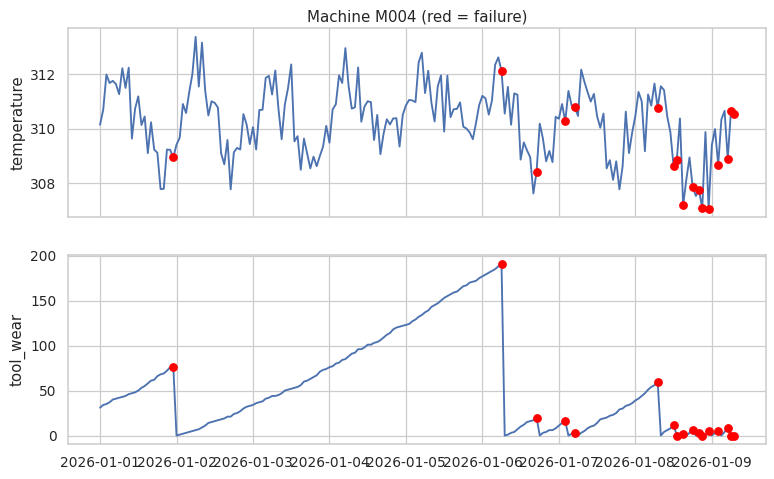

In [8]:
worst = df.groupby(config.COL_MACHINE)[config.COL_FAILURE].sum().idxmax()
m = df[df[config.COL_MACHINE] == worst]
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a, c in zip(ax, [config.COL_TEMP, config.COL_WEAR]):
    a.plot(m[config.COL_TIME], m[c])
    f = m[m[config.COL_FAILURE] == 1]
    a.scatter(f[config.COL_TIME], f[c], color='red', zorder=3)
    a.set_ylabel(c)
ax[0].set_title(f'Machine {worst} (red = failure)')
plt.show()

## Failure type ke hisaab se sensor behaviour
Har failure type ka physical reason alag hai, isliye sensors bhi alag tareeke se badalte hain:
- **Tool Wear Failure** -> tool_wear bahut high
- **Heat Dissipation Failure** -> process temp - air temp ka gap kam / rotational speed low
- **Power Failure** -> power (torque x speed) normal band se bahar
- **Overstrain Failure** -> tool_wear x torque bahut high

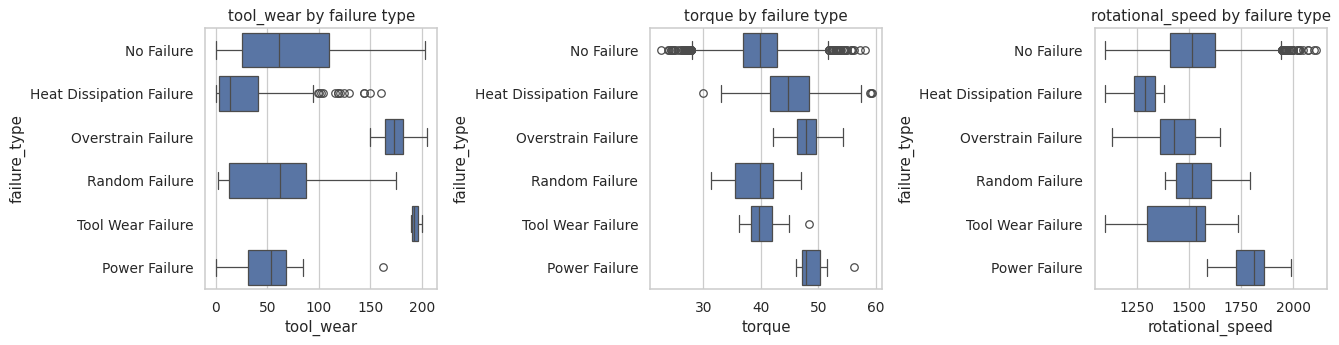

In [9]:
order = df[df[config.COL_FAILURE]==1][config.COL_FAILURE_TYPE].value_counts().index
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, [config.COL_WEAR, config.COL_TORQUE, config.COL_SPEED]):
    sns.boxplot(data=df[df[config.COL_FAILURE_TYPE].isin(list(order)+['No Failure'])],
                y=config.COL_FAILURE_TYPE, x=col, ax=ax, order=['No Failure']+list(order))
    ax.set_title(col + ' by failure type')
plt.tight_layout(); plt.show()

## Machine type (L / M / H) ke hisaab se failure rate

In [10]:
rate = df.groupby(config.COL_TYPE)[config.COL_FAILURE].agg(['mean','sum','count'])
rate['mean'] = (rate['mean']*100).round(2)
rate.rename(columns={'mean':'failure_rate_%','sum':'failures','count':'rows'})

,failure_rate_%,failures,rows
machine_type,,,
H,4.83,29,600
L,2.60,109,4200
M,3.04,158,5200


## Key observations (EDA se nikle points)
1. **Class imbalance**: failures sirf ~3% hain, isliye accuracy misleading hai (always-healthy model bhi ~97% accuracy deta hai). Hum Precision, Recall, F1, ROC-AUC aur PR-AUC use karte hain.
2. **Sensors akele weak hain**: healthy aur failed readings ke distributions bahut overlap karte hain -> engineered features (temp_diff, power, rolling trend) zaroori hain.
3. **Tool wear** aur **torque** ka failure se strongest relation dikhta hai, jo physical sense banata hai (ghisa hua tool + zyada load).
4. **Temperature Kelvin me hai** (e.g. 300 K ~ 27 C); process temperature hamesha air temperature se thoda upar rehti hai (~10 K gap).
5. Data me missing values / duplicates nahi hain, phir bhi `clean()` impossible values hata deta hai (real sensors ke liye safe).